In [2]:
from pathlib import Path
import pandas as pd

PROJETO = Path.cwd().resolve().parent

PASTA_RAW = PROJETO / "data" / "raw"

print("Projeto:", PROJETO)
print("Pasta encontrada:", PASTA_RAW.exists())

Projeto: /home/mjulia18/base_de_dados_aberta/renacee-avaliacao-anual
Pasta encontrada: True


In [3]:
arquivos = sorted(PASTA_RAW.glob("*.csv"))

print(f"Total de arquivos CSV: {len(arquivos)}")

for arquivo in arquivos:
    print(arquivo.name)

Total de arquivos CSV: 25
ANALITICA_avaliacao_com_perfil_sem_abertas.csv
ANALITICA_avaliacao_geral_sem_abertas.csv
ANALITICA_perfis_harmonizados_sem_abertas.csv
auditoria_vinculacao.csv
base_avaliacoes_2025.csv
base_grupo_EB.csv
base_grupo_GRAD.csv
base_grupo_POS.csv
base_grupo_PROF_EB.csv
base_grupo_PROF_IES.csv
base_integrada_auditoria_2025.csv
base_pareada_perfil_avaliacao_2025.csv
catalogo_colunas.csv
conferencia_registros_incluidos.csv
dicionario_perfil_harmonizado.csv
excecoes_revisar.csv
inventario_fontes.csv
mapeamento_original_consolidado.csv
matriz_equivalencias_verificadas.csv
pendencias_mapeamento_perfil.csv
qa_ausencias_variaveis_analiticas.csv
qa_harmonizacao_grupos.csv
qa_idade_perfil.csv
qa_identificadores_consentimento.csv
qa_likert.csv


In [8]:
arquivo = PASTA_RAW / "ANALITICA_avaliacao_geral_sem_abertas.csv"

df = pd.read_csv(
    arquivo,
    dtype=str,
    encoding="utf-8-sig"
)

display(df.head())

,ID,grupo,expectativas,desistencia_projeto,continuar_projeto,representatividade,motivacao_futuro,ampliacao_oportunidades,interesse_computacao_pos,conhecimento_computacao_pos,...,ano_escolar_eb,turno_estudo_eb,semestre_graduacao_pos,primeira_geracao_ensino_superior,primeira_geracao_pos_graduacao,area_docencia,experiencia_docente,laboratorio_escola,acesso_estudantes_tecnologia,perfil_disponivel
0,PEB11,EB,5,Não,Sim,5.0,3.0,3.0,Moderado,Moderado,...,9° ano - Ensino Fundamental,Tarde,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
1,PEB12,EB,5,Não,Sim,5.0,5.0,5.0,Muito,Moderado,...,8° ano - Ensino Fundamental,Tarde,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
2,PEB16,EB,4,Não,Talvez,4.0,4.0,3.0,Moderado,Moderado,...,2° ano - Ensino Médio,Tarde,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
3,PEB17,EB,4,Não,Talvez,5.0,4.0,2.0,Moderado,Moderado,...,3° ano - Ensino Médio,Manhã,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
4,PEB19,EB,4,Não,Sim,4.0,4.0,4.0,Moderado,Pouco,...,2° ano - Ensino Médio,Manhã,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True


In [5]:
print("Quantidade de linhas:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

Quantidade de linhas: 92
Quantidade de colunas: 35


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 35 columns):
 #   Column                                  Non-Null Count  Dtype
---  ------                                  --------------  -----
 0   ID                                      92 non-null     str  
 1   grupo                                   92 non-null     str  
 2   expectativas                            92 non-null     str  
 3   desistencia_projeto                     92 non-null     str  
 4   continuar_projeto                       92 non-null     str  
 5   representatividade                      69 non-null     str  
 6   motivacao_futuro                        69 non-null     str  
 7   ampliacao_oportunidades                 69 non-null     str  
 8   interesse_computacao_pos                49 non-null     str  
 9   conhecimento_computacao_pos             49 non-null     str  
 10  frequencia_computacao_pos               49 non-null     str  
 11  perspectivas_percebidas_multirre

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 35 columns):
 #   Column                                  Non-Null Count  Dtype
---  ------                                  --------------  -----
 0   ID                                      92 non-null     str  
 1   grupo                                   92 non-null     str  
 2   expectativas                            92 non-null     str  
 3   desistencia_projeto                     92 non-null     str  
 4   continuar_projeto                       92 non-null     str  
 5   representatividade                      69 non-null     str  
 6   motivacao_futuro                        69 non-null     str  
 7   ampliacao_oportunidades                 69 non-null     str  
 8   interesse_computacao_pos                49 non-null     str  
 9   conhecimento_computacao_pos             49 non-null     str  
 10  frequencia_computacao_pos               49 non-null     str  
 11  perspectivas_percebidas_multirre

In [9]:
resumo_colunas = pd.DataFrame({
    "coluna": df.columns,
    "preenchidos": df.notna().sum().values,
    "ausentes": df.isna().sum().values,
    "valores_unicos": df.nunique(dropna=True).values
})

display(resumo_colunas)

,coluna,preenchidos,ausentes,valores_unicos
0,ID,92,0,92
1,grupo,92,0,5
2,expectativas,92,0,4
3,desistencia_projeto,92,0,4
4,continuar_projeto,92,0,4
5,representatividade,69,23,3
6,motivacao_futuro,69,23,4
7,ampliacao_oportunidades,69,23,4
8,interesse_computacao_pos,49,43,3
9,conhecimento_computacao_pos,49,43,3


In [10]:
df["grupo"].unique()

<StringArray>
['EB', 'GRAD', 'POS', 'PROF_EB', 'PROF_IES']
Length: 5, dtype: str

In [11]:
df["grupo"].value_counts()

grupo
EB          49
GRAD        16
PROF_EB     14
PROF_IES     9
POS          4
Name: count, dtype: int64

In [12]:
df["expectativas"].value_counts(dropna=False)

expectativas
5    67
4    21
3     3
2     1
Name: count, dtype: int64

In [13]:
df["representatividade"].value_counts(dropna=False)

representatividade
5.0    46
NaN    23
4.0    18
3.0     5
Name: count, dtype: int64

In [14]:
pd.crosstab(
    df["grupo"],
    df["representatividade"].isna(),
    margins=True
)

representatividade,False,True,All
grupo,,,
EB,49,0,49
GRAD,16,0,16
POS,4,0,4
PROF_EB,0,14,14
PROF_IES,0,9,9
All,69,23,92


In [15]:
df["grupo"].value_counts(dropna=False)

grupo
EB          49
GRAD        16
PROF_EB     14
PROF_IES     9
POS          4
Name: count, dtype: int64

In [16]:
percentuais_expectativas = pd.crosstab(
    df["grupo"],
    df["expectativas"],
    normalize="index"
) * 100

display(percentuais_expectativas.round(2))

expectativas,2,3,4,5
grupo,,,,
EB,2.04,2.04,30.61,65.31
GRAD,0.00,0.00,12.50,87.50
POS,0.00,0.00,25.00,75.00
PROF_EB,0.00,7.14,21.43,71.43
PROF_IES,0.00,11.11,0.00,88.89


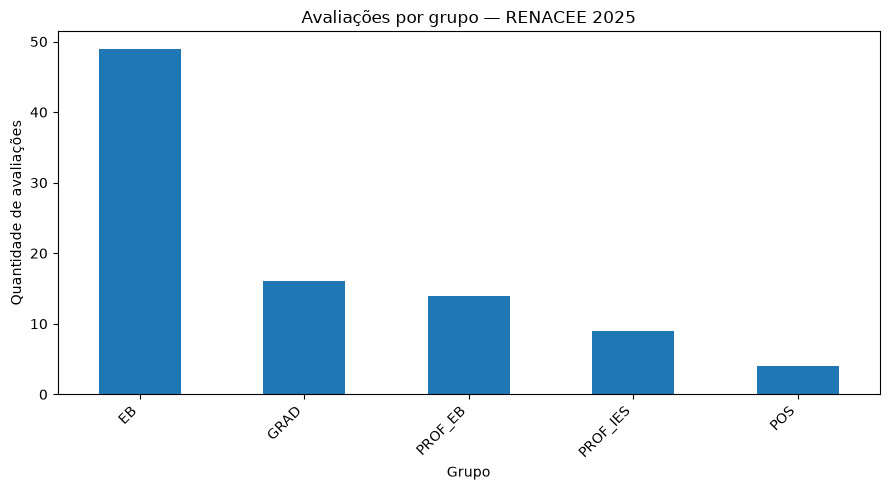

In [17]:
import matplotlib.pyplot as plt

contagem = df["grupo"].value_counts()

ax = contagem.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title("Avaliações por grupo — RENACEE 2025")
ax.set_xlabel("Grupo")
ax.set_ylabel("Quantidade de avaliações")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [20]:
def explorar_coluna(dados, coluna):
    print(f"VARIÁVEL: {coluna}")
    print("-" * 45)

    print("Total de registros:", len(dados))
    print("Preenchidos:", dados[coluna].notna().sum())
    print("Ausentes:", dados[coluna].isna().sum())

    print("\nDistribuição dos valores:")
    display(
        dados[coluna]
        .value_counts(dropna=False)
        .rename_axis("resposta")
        .reset_index(name="quantidade")
    )

In [21]:
explorar_coluna(df, "expectativas")
explorar_coluna(df, "desistencia_projeto")
explorar_coluna(df, "continuar_projeto")

VARIÁVEL: expectativas
---------------------------------------------
Total de registros: 92
Preenchidos: 92
Ausentes: 0

Distribuição dos valores:


,resposta,quantidade
0,5,67
1,4,21
2,3,3
3,2,1


VARIÁVEL: desistencia_projeto
---------------------------------------------
Total de registros: 92
Preenchidos: 92
Ausentes: 0

Distribuição dos valores:


,resposta,quantidade
0,Não,71
1,Prefiro não responder,12
2,"Sim, uma vez",6
3,"Sim, mais de uma vez",3


VARIÁVEL: continuar_projeto
---------------------------------------------
Total de registros: 92
Preenchidos: 92
Ausentes: 0

Distribuição dos valores:


,resposta,quantidade
0,Sim,70
1,Talvez,18
2,Não,3
3,"Estou no 1° , e não posso mais fazer parte, ma...",1


In [22]:
from pathlib import Path
import pandas as pd

# Considerando o notebook dentro de notebooks/
PROJETO = Path.cwd().resolve().parent
PASTA_RAW = PROJETO / "data" / "raw"

df_avaliacao = pd.read_csv(
    PASTA_RAW / "ANALITICA_avaliacao_geral_sem_abertas.csv",
    dtype=str,
    encoding="utf-8-sig"
)

df_perfis = pd.read_csv(
    PASTA_RAW / "ANALITICA_perfis_harmonizados_sem_abertas.csv",
    dtype=str,
    encoding="utf-8-sig"
)

df_pareada = pd.read_csv(
    PASTA_RAW / "ANALITICA_avaliacao_com_perfil_sem_abertas.csv",
    dtype=str,
    encoding="utf-8-sig"
)

print("Avaliações:", df_avaliacao.shape)
print("Perfis:", df_perfis.shape)
print("Pareada:", df_pareada.shape)

Avaliações: (92, 35)
Perfis: (130, 23)
Pareada: (80, 35)


In [23]:
def inventariar_base(dados):
    inventario = pd.DataFrame({
        "coluna": dados.columns,
        "tipo": dados.dtypes.astype(str).values,
        "preenchidos": dados.notna().sum().values,
        "ausentes": dados.isna().sum().values,
        "percentual_ausente": (
            dados.isna().mean().values * 100
        ).round(2),
        "valores_distintos": dados.nunique(dropna=True).values
    })

    return inventario

In [24]:
inventario_avaliacao = inventariar_base(df_avaliacao)
inventario_perfis = inventariar_base(df_perfis)
inventario_pareada = inventariar_base(df_pareada)

display(inventario_perfis)

,coluna,tipo,preenchidos,ausentes,percentual_ausente,valores_distintos
0,ID,str,130,0,0.00,130
1,grupo,str,130,0,0.00,4
2,idade,str,128,2,1.54,28
3,raca_etnia,str,130,0,0.00,4
4,genero,str,14,116,89.23,2
5,cidade_uf,str,130,0,0.00,19
6,renda_familiar_faixa_sm,str,130,0,0.00,4
7,beneficios_sociais_multirresposta,str,130,0,0.00,10
8,dispositivos_multirresposta,str,130,0,0.00,6
9,internet_domestica_multirresposta,str,130,0,0.00,8


In [25]:
def frequencia(dados, coluna):
    resultado = (
        dados[coluna]
        .value_counts(dropna=False)
        .rename_axis("resposta")
        .reset_index(name="quantidade")
    )

    resultado["percentual"] = (
        resultado["quantidade"] / len(dados) * 100
    ).round(2)

    return resultado

In [26]:
display(frequencia(df_avaliacao, "grupo"))
display(frequencia(df_perfis, "grupo"))
display(frequencia(df_pareada, "grupo"))

,resposta,quantidade,percentual
0,EB,49,53.26
1,GRAD,16,17.39
2,PROF_EB,14,15.22
3,PROF_IES,9,9.78
4,POS,4,4.35


,resposta,quantidade,percentual
0,EB,74,56.92
1,GRAD,37,28.46
2,PROF_EB,14,10.77
3,POS,5,3.85


,resposta,quantidade,percentual
0,EB,46,57.5
1,GRAD,16,20.0
2,PROF_EB,14,17.5
3,POS,4,5.0


In [27]:
display(frequencia(df_avaliacao, "expectativas"))
display(frequencia(df_avaliacao, "continuar_projeto"))
display(frequencia(df_avaliacao, "desistencia_projeto"))

,resposta,quantidade,percentual
0,5,67,72.83
1,4,21,22.83
2,3,3,3.26
3,2,1,1.09


,resposta,quantidade,percentual
0,Sim,70,76.09
1,Talvez,18,19.57
2,Não,3,3.26
3,"Estou no 1° , e não posso mais fazer parte, ma...",1,1.09


,resposta,quantidade,percentual
0,Não,71,77.17
1,Prefiro não responder,12,13.04
2,"Sim, uma vez",6,6.52
3,"Sim, mais de uma vez",3,3.26


In [28]:
for numero, coluna in enumerate(df_perfis.columns, 1):
    print(f"{numero:02d} - {coluna}")

01 - ID
02 - grupo
03 - idade
04 - raca_etnia
05 - genero
06 - cidade_uf
07 - renda_familiar_faixa_sm
08 - beneficios_sociais_multirresposta
09 - dispositivos_multirresposta
10 - internet_domestica_multirresposta
11 - espaco_estudo
12 - distancia_deslocamento
13 - responsabilidades_familiares_original
14 - instituicao_vinculo
15 - ano_escolar_eb
16 - turno_estudo_eb
17 - semestre_graduacao_pos
18 - primeira_geracao_ensino_superior
19 - primeira_geracao_pos_graduacao
20 - area_docencia
21 - experiencia_docente
22 - laboratorio_escola
23 - acesso_estudantes_tecnologia


In [29]:
colunas_avaliacao = set(df_avaliacao.columns)
colunas_perfis = set(df_perfis.columns)
colunas_pareada = set(df_pareada.columns)

print("Colunas comuns à avaliação e aos perfis:")
print(sorted(colunas_avaliacao & colunas_perfis))

print("\nColunas exclusivas da avaliação:")
print(sorted(colunas_avaliacao - colunas_perfis))

print("\nColunas exclusivas dos perfis:")
print(sorted(colunas_perfis - colunas_avaliacao))

print("\nColunas exclusivas da base pareada:")
print(sorted(colunas_pareada - colunas_avaliacao))

Colunas comuns à avaliação e aos perfis:
['ID', 'acesso_estudantes_tecnologia', 'ano_escolar_eb', 'area_docencia', 'beneficios_sociais_multirresposta', 'cidade_uf', 'dispositivos_multirresposta', 'distancia_deslocamento', 'espaco_estudo', 'experiencia_docente', 'genero', 'grupo', 'idade', 'instituicao_vinculo', 'internet_domestica_multirresposta', 'laboratorio_escola', 'primeira_geracao_ensino_superior', 'primeira_geracao_pos_graduacao', 'raca_etnia', 'renda_familiar_faixa_sm', 'responsabilidades_familiares_original', 'semestre_graduacao_pos', 'turno_estudo_eb']

Colunas exclusivas da avaliação:
['ampliacao_oportunidades', 'conhecimento_computacao_pos', 'continuar_projeto', 'desistencia_projeto', 'etapas_interseccionalidade_docencia', 'expectativas', 'frequencia_computacao_pos', 'interesse_computacao_pos', 'motivacao_futuro', 'perfil_disponivel', 'perspectivas_percebidas_multirresposta', 'representatividade']

Colunas exclusivas dos perfis:
[]

Colunas exclusivas da base pareada:
[]


In [30]:
def verificar_ids(dados, nome):
    return {
        "base": nome,
        "registros": len(dados),
        "ids_ausentes": dados["ID"].isna().sum(),
        "ids_duplicados": dados["ID"].duplicated().sum(),
        "ids_distintos": dados["ID"].nunique()
    }

resumo_ids = pd.DataFrame([
    verificar_ids(df_avaliacao, "Avaliação"),
    verificar_ids(df_perfis, "Perfis"),
    verificar_ids(df_pareada, "Pareada")
])

display(resumo_ids)

,base,registros,ids_ausentes,ids_duplicados,ids_distintos
0,Avaliação,92,0,0,92
1,Perfis,130,0,0,130
2,Pareada,80,0,0,80


In [31]:
ids_avaliacao = set(df_avaliacao["ID"].dropna())
ids_perfis = set(df_perfis["ID"].dropna())
ids_pareada = set(df_pareada["ID"].dropna())

print("IDs presentes nas duas bases:",
      len(ids_avaliacao & ids_perfis))

print("Avaliações sem perfil:",
      len(ids_avaliacao - ids_perfis))

print("Perfis sem avaliação:",
      len(ids_perfis - ids_avaliacao))

print("IDs da base pareada:",
      len(ids_pareada))

print("Base pareada corresponde à interseção?",
      ids_pareada == (ids_avaliacao & ids_perfis))

IDs presentes nas duas bases: 80
Avaliações sem perfil: 12
Perfis sem avaliação: 50
IDs da base pareada: 80
Base pareada corresponde à interseção? True


In [32]:
PASTA_REPORTS = PROJETO / "reports"
PASTA_REPORTS.mkdir(exist_ok=True)

caminho_relatorio = (
    PASTA_REPORTS / "exploracao_inicial_renacee_2025.xlsx"
)

resumo_bases = pd.DataFrame([
    {
        "base": "Avaliação geral",
        "linhas": len(df_avaliacao),
        "colunas": len(df_avaliacao.columns)
    },
    {
        "base": "Perfis harmonizados",
        "linhas": len(df_perfis),
        "colunas": len(df_perfis.columns)
    },
    {
        "base": "Avaliação com perfil",
        "linhas": len(df_pareada),
        "colunas": len(df_pareada.columns)
    }
])

with pd.ExcelWriter(caminho_relatorio, engine="openpyxl") as writer:
    resumo_bases.to_excel(
        writer, sheet_name="Resumo_Bases", index=False
    )

    inventario_avaliacao.to_excel(
        writer, sheet_name="Inventario_Avaliacao", index=False
    )

    inventario_perfis.to_excel(
        writer, sheet_name="Inventario_Perfis", index=False
    )

    inventario_pareada.to_excel(
        writer, sheet_name="Inventario_Pareada", index=False
    )

    resumo_ids.to_excel(
        writer, sheet_name="Verificacao_IDs", index=False
    )

print("Relatório salvo em:", caminho_relatorio)

Relatório salvo em: /home/mjulia18/base_de_dados_aberta/renacee-avaliacao-anual/reports/exploracao_inicial_renacee_2025.xlsx


In [33]:
variaveis_controle = [
    "ID",
    "grupo",
    "perfil_disponivel"
]

variaveis_avaliacao = [
    "expectativas",
    "desistencia_projeto",
    "continuar_projeto",
    "representatividade",
    "motivacao_futuro",
    "ampliacao_oportunidades",
    "interesse_computacao_pos",
    "conhecimento_computacao_pos",
    "frequencia_computacao_pos",
    "perspectivas_percebidas_multirresposta",
    "etapas_interseccionalidade_docencia"
]

variaveis_perfil = [
    coluna
    for coluna in df_perfis.columns
    if coluna not in ["ID", "grupo"]
]

In [34]:
def classificar_variavel(coluna):
    if coluna in variaveis_controle:
        return "Identificação e controle"

    if coluna in variaveis_avaliacao:
        return "Avaliação"

    if coluna in variaveis_perfil:
        return "Perfil"

    return "Não classificada"


mapa_variaveis = pd.DataFrame({
    "variavel": df_avaliacao.columns
})

mapa_variaveis["categoria"] = (
    mapa_variaveis["variavel"].apply(classificar_variavel)
)

mapa_variaveis["preenchidos"] = [
    df_avaliacao[coluna].notna().sum()
    for coluna in mapa_variaveis["variavel"]
]

mapa_variaveis["ausentes"] = [
    df_avaliacao[coluna].isna().sum()
    for coluna in mapa_variaveis["variavel"]
]

display(mapa_variaveis)

,variavel,categoria,preenchidos,ausentes
0,ID,Identificação e controle,92,0
1,grupo,Identificação e controle,92,0
2,expectativas,Avaliação,92,0
3,desistencia_projeto,Avaliação,92,0
4,continuar_projeto,Avaliação,92,0
5,representatividade,Avaliação,69,23
6,motivacao_futuro,Avaliação,69,23
7,ampliacao_oportunidades,Avaliação,69,23
8,interesse_computacao_pos,Avaliação,49,43
9,conhecimento_computacao_pos,Avaliação,49,43


In [35]:
print(mapa_variaveis["categoria"].value_counts())

print(
    "Variáveis não classificadas:",
    mapa_variaveis.loc[
        mapa_variaveis["categoria"] == "Não classificada",
        "variavel"
    ].tolist()
)

categoria
Perfil                      21
Avaliação                   11
Identificação e controle     3
Name: count, dtype: int64
Variáveis não classificadas: []


In [ ]:
from pathlib import Path
import pandas as pd

PROJETO = Path.cwd().resolve().parent

PASTA_RAW2 = PROJETO / "data" / "raw2"

df_dicionario = pd.read_csv(
    PASTA_RAW2 / "dicionario_perfil_harmonizado.csv"
)

df_equivalencias = pd.read_csv(
    PASTA_RAW2 / "matriz_equivalencias_verificadas.csv"
)

display(df_dicionario.head(10))
display(df_equivalencias.head(10))

,variavel_padronizada,classe_equivalencia,fonte,grupo,coluna_original,mapeamento_previsto,coluna_encontrada
0,idade,comparavel,perfil_eb,EB,Qual sua idade?,True,True
1,idade,comparavel,perfil_grad,GRAD,Qual sua idade?,True,True
2,idade,comparavel,perfil_pos,POS,Qual sua idade?,True,True
3,idade,comparavel,perfil_prof_eb,PROF_EB,Qual sua idade?,True,True
4,raca_etnia,comparavel,perfil_eb,EB,Qual sua raça/etnia?,True,True
5,raca_etnia,comparavel,perfil_grad,GRAD,Qual sua raça/etnia?,True,True
6,raca_etnia,comparavel,perfil_pos,POS,Qual sua raça/etnia?,True,True
7,raca_etnia,comparavel,perfil_prof_eb,PROF_EB,Qual sua raça/etnia?,True,True
8,genero,comparavel,perfil_eb,EB,NaN,False,False
9,genero,comparavel,perfil_grad,GRAD,Com qual gênero você se identifica?,True,True


,fonte,variavel_harmonizada,coluna_original,disponivel
0,aval_eb,expectativas,O RENACEE_MD tem atendido suas expectativas?,True
1,aval_eb,desistencia_projeto,"Em algum momento, você considerou desistir de ...",True
2,aval_eb,continuar_projeto,Você pretende continuar participando do ReNacE...,True
3,aval_eb,representatividade,Você se sente representada nas ações e materia...,True
4,aval_eb,motivacao_futuro,Você se sente mais motivada em relação ao seu ...,True
5,aval_eb,ampliacao_oportunidades,O RENACEE_MD contribuiu para ampliar suas opor...,True
6,aval_superior,expectativas,O RENACEE_MD tem atendido suas expectativas.,True
7,aval_superior,desistencia_projeto,"Em algum momento, você considerou desistir de ...",True
8,aval_superior,continuar_projeto,Você pretende continuar participando do ReNacE...,True
9,aval_superior,representatividade,Você se sente representada nas ações e materia...,True


In [41]:
print("Pasta encontrada:", PASTA_RAW2.exists())

print(
    "Dicionário encontrado:",
    (PASTA_RAW2 / "dicionario_perfil_harmonizado.csv").exists()
)

print(
    "Matriz encontrada:",
    (PASTA_RAW2 / "matriz_equivalencias_verificadas.csv").exists()
)

Pasta encontrada: True
Dicionário encontrado: True
Matriz encontrada: True


In [42]:
print("DICIONÁRIO DE PERFIL")
print("Dimensões:", df_dicionario.shape)
print("Colunas:", df_dicionario.columns.tolist())

print("\nMATRIZ DE EQUIVALÊNCIAS")
print("Dimensões:", df_equivalencias.shape)
print("Colunas:", df_equivalencias.columns.tolist())

DICIONÁRIO DE PERFIL
Dimensões: (84, 7)
Colunas: ['variavel_padronizada', 'classe_equivalencia', 'fonte', 'grupo', 'coluna_original', 'mapeamento_previsto', 'coluna_encontrada']

MATRIZ DE EQUIVALÊNCIAS
Dimensões: (18, 4)
Colunas: ['fonte', 'variavel_harmonizada', 'coluna_original', 'disponivel']


In [43]:
print(df_dicionario["variavel_padronizada"].unique())

<StringArray>
[                                'idade',
                            'raca_etnia',
                                'genero',
                             'cidade_uf',
               'renda_familiar_faixa_sm',
     'beneficios_sociais_multirresposta',
           'dispositivos_multirresposta',
     'internet_domestica_multirresposta',
                         'espaco_estudo',
                'distancia_deslocamento',
 'responsabilidades_familiares_original',
                   'instituicao_vinculo',
                        'ano_escolar_eb',
                       'turno_estudo_eb',
                'semestre_graduacao_pos',
      'primeira_geracao_ensino_superior',
        'primeira_geracao_pos_graduacao',
                         'area_docencia',
                   'experiencia_docente',
                    'laboratorio_escola',
          'acesso_estudantes_tecnologia']
Length: 21, dtype: str


In [44]:
df_dicionario["variavel_padronizada"].value_counts()

variavel_padronizada
idade                                    4
raca_etnia                               4
genero                                   4
cidade_uf                                4
renda_familiar_faixa_sm                  4
beneficios_sociais_multirresposta        4
dispositivos_multirresposta              4
internet_domestica_multirresposta        4
espaco_estudo                            4
distancia_deslocamento                   4
responsabilidades_familiares_original    4
instituicao_vinculo                      4
ano_escolar_eb                           4
turno_estudo_eb                          4
semestre_graduacao_pos                   4
primeira_geracao_ensino_superior         4
primeira_geracao_pos_graduacao           4
area_docencia                            4
experiencia_docente                      4
laboratorio_escola                       4
acesso_estudantes_tecnologia             4
Name: count, dtype: int64

In [45]:
df_dicionario.loc[
    df_dicionario["variavel_padronizada"] == "idade"
]

,variavel_padronizada,classe_equivalencia,fonte,grupo,coluna_original,mapeamento_previsto,coluna_encontrada
0,idade,comparavel,perfil_eb,EB,Qual sua idade?,True,True
1,idade,comparavel,perfil_grad,GRAD,Qual sua idade?,True,True
2,idade,comparavel,perfil_pos,POS,Qual sua idade?,True,True
3,idade,comparavel,perfil_prof_eb,PROF_EB,Qual sua idade?,True,True


In [46]:
df_dicionario.loc[
    df_dicionario["variavel_padronizada"] == "genero"
]

,variavel_padronizada,classe_equivalencia,fonte,grupo,coluna_original,mapeamento_previsto,coluna_encontrada
8,genero,comparavel,perfil_eb,EB,NaN,False,False
9,genero,comparavel,perfil_grad,GRAD,Com qual gênero você se identifica?,True,True
10,genero,comparavel,perfil_pos,POS,Com qual gênero você se identifica?,True,True
11,genero,comparavel,perfil_prof_eb,PROF_EB,Com qual gênero você se identifica?,True,True


In [47]:
display(df_equivalencias)

,fonte,variavel_harmonizada,coluna_original,disponivel
0,aval_eb,expectativas,O RENACEE_MD tem atendido suas expectativas?,True
1,aval_eb,desistencia_projeto,"Em algum momento, você considerou desistir de ...",True
2,aval_eb,continuar_projeto,Você pretende continuar participando do ReNacE...,True
3,aval_eb,representatividade,Você se sente representada nas ações e materia...,True
4,aval_eb,motivacao_futuro,Você se sente mais motivada em relação ao seu ...,True
5,aval_eb,ampliacao_oportunidades,O RENACEE_MD contribuiu para ampliar suas opor...,True
6,aval_superior,expectativas,O RENACEE_MD tem atendido suas expectativas.,True
7,aval_superior,desistencia_projeto,"Em algum momento, você considerou desistir de ...",True
8,aval_superior,continuar_projeto,Você pretende continuar participando do ReNacE...,True
9,aval_superior,representatividade,Você se sente representada nas ações e materia...,True


In [48]:
if "variavel_harmonizada" in df_equivalencias.columns:
    print(
        df_equivalencias["variavel_harmonizada"]
        .dropna()
        .unique()
    )

<StringArray>
[           'expectativas',     'desistencia_projeto',
       'continuar_projeto',      'representatividade',
        'motivacao_futuro', 'ampliacao_oportunidades']
Length: 6, dtype: str


In [50]:
# 1. Reunir os mapeamentos documentados
origens_perfil = df_dicionario[
    ["variavel_padronizada", "grupo", "coluna_original"]
].rename(columns={
    "variavel_padronizada": "variavel"
})

origens_avaliacao = df_equivalencias[
    ["variavel_harmonizada", "fonte", "coluna_original"]
].rename(columns={
    "variavel_harmonizada": "variavel"
})

# 2. Criar o mapa das três bases
bases = {
    "avaliacao_geral": df_avaliacao,
    "perfis_harmonizados": df_perfis,
    "avaliacao_com_perfil": df_pareada
}

registros = []

for nome_base, dados in bases.items():
    for coluna in dados.columns:
        registros.append({
            "base": nome_base,
            "variavel": coluna,
            "pergunta_origem": "",
            "registros": len(dados),
            "preenchidos": dados[coluna].notna().sum(),
            "ausentes": dados[coluna].isna().sum(),
            "valores_distintos": dados[coluna].nunique(dropna=True)
        })

mapa_variaveis = pd.DataFrame(registros)

# 3. Criar um resumo das perguntas originais
def resumir_origens(tabela, identificador):
    tabela = tabela.dropna(
        subset=["variavel", "coluna_original"]
    ).copy()

    tabela["origem"] = (
        tabela[identificador].astype(str)
        + ": "
        + tabela["coluna_original"].astype(str)
    )

    return tabela.groupby("variavel")["origem"].apply(
        lambda valores: " | ".join(sorted(set(valores)))
    )

perguntas_perfil = resumir_origens(
    origens_perfil, "grupo"
)

perguntas_avaliacao = resumir_origens(
    origens_avaliacao, "fonte"
)

# 4. Preencher a pergunta de origem conforme a variável
for indice, linha in mapa_variaveis.iterrows():
    variavel = linha["variavel"]

    if variavel in perguntas_avaliacao.index:
        mapa_variaveis.at[
            indice, "pergunta_origem"
        ] = perguntas_avaliacao[variavel]

    elif variavel in perguntas_perfil.index:
        mapa_variaveis.at[
            indice, "pergunta_origem"
        ] = perguntas_perfil[variavel]

display(mapa_variaveis)

,base,variavel,pergunta_origem,registros,preenchidos,ausentes,valores_distintos
0,avaliacao_geral,ID,,92,92,0,92
1,avaliacao_geral,grupo,,92,92,0,5
2,avaliacao_geral,expectativas,aval_eb: O RENACEE_MD tem atendido suas expect...,92,92,0,4
3,avaliacao_geral,desistencia_projeto,"aval_eb: Em algum momento, você considerou des...",92,92,0,4
4,avaliacao_geral,continuar_projeto,aval_eb: Você pretende continuar participando ...,92,92,0,4
...,...,...,...,...,...,...,...
88,avaliacao_com_perfil,area_docencia,PROF_EB: Em qual área de conhecimento você lec...,80,14,66,5
89,avaliacao_com_perfil,experiencia_docente,PROF_EB: Há quanto tempo você atua como profes...,80,14,66,3
90,avaliacao_com_perfil,laboratorio_escola,"PROF_EB: Na sua escola, há laboratórios ou equ...",80,14,66,4
91,avaliacao_com_perfil,acesso_estudantes_tecnologia,PROF_EB: Seus estudantes tem acesso à tecnolog...,80,14,66,3


In [51]:
mapa_variaveis.to_csv(
    PASTA_REPORTS / "mapa_variaveis_inicial.csv",
    index=False,
    encoding="utf-8-sig"
)

In [52]:
import pandas as pd
from pathlib import Path

# 1. Bases analíticas
bases = {
    "avaliacao_geral": df_avaliacao,
    "perfis_harmonizados": df_perfis,
    "avaliacao_com_perfil": df_pareada
}

# 2. Classificação das variáveis
variaveis_controle = {
    "ID", "grupo", "perfil_disponivel"
}

variaveis_avaliacao = {
    "expectativas",
    "desistencia_projeto",
    "continuar_projeto",
    "representatividade",
    "motivacao_futuro",
    "ampliacao_oportunidades",
    "interesse_computacao_pos",
    "conhecimento_computacao_pos",
    "frequencia_computacao_pos",
    "perspectivas_percebidas_multirresposta",
    "etapas_interseccionalidade_docencia"
}

variaveis_perfil = set(df_perfis.columns) - {"ID", "grupo"}

def classificar_variavel(variavel):
    if variavel in variaveis_controle:
        return "Identificação e controle"
    if variavel in variaveis_avaliacao:
        return "Avaliação"
    if variavel in variaveis_perfil:
        return "Perfil"
    return "Não classificada"


# 3. Reunir as perguntas originais documentadas
origens_perfil = df_dicionario.rename(columns={
    "variavel_padronizada": "variavel",
    "grupo": "grupo_origem",
    "coluna_original": "pergunta_origem",
    "coluna_encontrada": "mapeamento_disponivel"
})[
    ["variavel", "grupo_origem",
     "pergunta_origem", "mapeamento_disponivel"]
].copy()

origens_avaliacao = df_equivalencias.rename(columns={
    "variavel_harmonizada": "variavel",
    "fonte": "grupo_origem",
    "coluna_original": "pergunta_origem",
    "disponivel": "mapeamento_disponivel"
})[
    ["variavel", "grupo_origem",
     "pergunta_origem", "mapeamento_disponivel"]
].copy()

# Preservar o tipo de origem
origens_perfil["tipo_origem"] = "Perfil"
origens_avaliacao["tipo_origem"] = "Avaliação"

mapa_origens = pd.concat(
    [origens_perfil, origens_avaliacao],
    ignore_index=True
).drop_duplicates()

# 4. Considerar somente mapeamentos encontrados
origens_disponiveis = mapa_origens[
    mapa_origens["mapeamento_disponivel"] == True
].copy()

# Resumir perguntas e grupos por variável
def juntar_valores(serie):
    valores = serie.dropna().astype(str).unique()
    return " | ".join(sorted(valores))

resumo_origens = (
    origens_disponiveis
    .groupby("variavel")
    .agg(
        pergunta_origem=("pergunta_origem", juntar_valores),
        grupo_origem=("grupo_origem", juntar_valores)
    )
    .reset_index()
)

# 5. Criar inventário das variáveis das bases
registros = []

for nome_base, dados in bases.items():
    for variavel in dados.columns:
        registros.append({
            "base": nome_base,
            "variavel": variavel,
            "categoria": classificar_variavel(variavel),
            "tipo_dado": str(dados[variavel].dtype),
            "registros": len(dados),
            "preenchidos": dados[variavel].notna().sum(),
            "ausentes": dados[variavel].isna().sum(),
            "valores_distintos": dados[variavel].nunique(dropna=True)
        })

mapa_variaveis = pd.DataFrame(registros)

# 6. Incorporar perguntas e grupos de origem
mapa_variaveis = mapa_variaveis.merge(
    resumo_origens,
    on="variavel",
    how="left",
    validate="many_to_one"
)

# Aplicabilidade documentada (não é cobertura real)
mapa_variaveis["aplicabilidade"] = mapa_variaveis["grupo_origem"]

# Identificar lacunas de documentação
mapa_variaveis["situacao_documentacao"] = (
    mapa_variaveis["pergunta_origem"]
    .notna()
    .map({
        True: "Origem documentada",
        False: "Origem não identificada nos dois mapeamentos"
    })
)

# 7. Organizar a ordem das colunas
colunas = [
    "base",
    "variavel",
    "pergunta_origem",
    "grupo_origem",
    "categoria",
    "tipo_dado",
    "aplicabilidade",
    "registros",
    "preenchidos",
    "ausentes",
    "valores_distintos",
    "situacao_documentacao"
]

mapa_variaveis = mapa_variaveis[colunas]

display(mapa_variaveis.head(15))

,base,variavel,pergunta_origem,grupo_origem,categoria,tipo_dado,aplicabilidade,registros,preenchidos,ausentes,valores_distintos,situacao_documentacao
0,avaliacao_geral,ID,NaN,NaN,Identificação e controle,str,NaN,92,92,0,92,Origem não identificada nos dois mapeamentos
1,avaliacao_geral,grupo,NaN,NaN,Identificação e controle,str,NaN,92,92,0,5,Origem não identificada nos dois mapeamentos
2,avaliacao_geral,expectativas,O RENACEE_MD tem atendido suas expectativas. |...,aval_eb | aval_prof | aval_superior,Avaliação,str,aval_eb | aval_prof | aval_superior,92,92,0,4,Origem documentada
3,avaliacao_geral,desistencia_projeto,"Em algum momento, você considerou desistir de ...",aval_eb | aval_prof | aval_superior,Avaliação,str,aval_eb | aval_prof | aval_superior,92,92,0,4,Origem documentada
4,avaliacao_geral,continuar_projeto,Você pretende continuar participando do ReNacE...,aval_eb | aval_prof | aval_superior,Avaliação,str,aval_eb | aval_prof | aval_superior,92,92,0,4,Origem documentada
5,avaliacao_geral,representatividade,Você se sente representada nas ações e materia...,aval_eb | aval_superior,Avaliação,str,aval_eb | aval_superior,92,69,23,3,Origem documentada
6,avaliacao_geral,motivacao_futuro,Você se sente mais motivada em relação ao seu ...,aval_eb | aval_superior,Avaliação,str,aval_eb | aval_superior,92,69,23,4,Origem documentada
7,avaliacao_geral,ampliacao_oportunidades,O RENACEE_MD contribuiu para ampliar suas opor...,aval_eb | aval_superior,Avaliação,str,aval_eb | aval_superior,92,69,23,4,Origem documentada
8,avaliacao_geral,interesse_computacao_pos,NaN,NaN,Avaliação,str,NaN,92,49,43,3,Origem não identificada nos dois mapeamentos
9,avaliacao_geral,conhecimento_computacao_pos,NaN,NaN,Avaliação,str,NaN,92,49,43,3,Origem não identificada nos dois mapeamentos


In [54]:
esperado = sum(len(dados.columns) for dados in bases.values())

print("Linhas esperadas:", esperado)
print("Linhas encontradas:", len(mapa_variaveis))

assert len(mapa_variaveis) == esperado

print("\nVariáveis por categoria:")
display(
    mapa_variaveis[["variavel", "categoria"]]
    .drop_duplicates()
    ["categoria"]
    .value_counts()
)

print("\nVariáveis sem pergunta original identificada:")
pendencias = mapa_variaveis.loc[
    mapa_variaveis["pergunta_origem"].isna(),
    ["variavel", "categoria"]
].drop_duplicates()

display(pendencias)

Linhas esperadas: 93
Linhas encontradas: 93

Variáveis por categoria:


categoria
Perfil                      21
Avaliação                   11
Identificação e controle     3
Name: count, dtype: int64


Variáveis sem pergunta original identificada:


,variavel,categoria
0,ID,Identificação e controle
1,grupo,Identificação e controle
8,interesse_computacao_pos,Avaliação
9,conhecimento_computacao_pos,Avaliação
10,frequencia_computacao_pos,Avaliação
11,perspectivas_percebidas_multirresposta,Avaliação
12,etapas_interseccionalidade_docencia,Avaliação
34,perfil_disponivel,Identificação e controle


In [ ]:
PASTA_REPORTS = PROJETO / "reports"
PASTA_REPORTS.mkdir(parents=True, exist_ok=True)

# Dicionário consolidado
mapa_variaveis.to_csv(
    PASTA_REPORTS / "dicionario_dados_consolidado.csv",
    index=False,
    encoding="utf-8-sig"
)

# Detalhamento das perguntas por origem
mapa_origens.to_csv(
    PASTA_REPORTS / "perguntas_origem_detalhadas.csv",
    index=False,
    encoding="utf-8-sig"
)

# Pendências documentais
pendencias.to_csv(
    PASTA_REPORTS / "pendencias_documentacao.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivos gerados com sucesso!")

In [55]:
PASTA_REPORTS = PROJETO / "reports"
PASTA_REPORTS.mkdir(parents=True, exist_ok=True)

mapa_variaveis.to_csv(
    PASTA_REPORTS / "dicionario_dados_consolidado.csv",
    index=False,
    encoding="utf-8-sig"
)

mapa_origens.to_csv(
    PASTA_REPORTS / "perguntas_origem_detalhadas.csv",
    index=False,
    encoding="utf-8-sig"
)

pendencias.to_csv(
    PASTA_REPORTS / "pendencias_documentacao.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivos gerados com sucesso!")

Arquivos gerados com sucesso!
